# Will This Visitor Buy? – Online Shopping Purchase Intention Prediction
**NextGen Institute · Machine Learning · Final Project (Idea 03)**

 **Individual Project by:** Zainab Reda · Dataset: [Online Shoppers Purchasing Intention (UCI)](https://archive.ics.uci.edu/dataset/468)

**How to run:** put the dataset CSV in the `data/` folder, then *Kernel → Restart & Run All*. Every number in this notebook is computed by the code below — copy your own numbers into the README, slides and LinkedIn post.

## 1 · Problem framing

**Who has the problem?** An e-commerce company whose visitors mostly leave without buying.

**Decision the model supports:** during a live session, decide what to show the visitor:
- *No action* — visitor is already very likely to buy (don't give away a discount),
- *Coupon* — visitor is undecided and might be tipped over,
- *Chat assistant* — visitor shows low intent and may just need help.

**Target:** `Revenue` (True = the session ended with a purchase).

**Metrics (and why):**
- **Accuracy is misleading** — only a minority of sessions end in a purchase, so a model that always says "no purchase" looks good but is useless.
- **ROC-AUC** and **PR-AUC (average precision)** to compare models independent of a threshold.
- **Precision / recall / F1 at a chosen threshold** for the actual business decision, where the threshold is tuned on *training* data only.

In [ ]:
import warnings, json, glob, os
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score, recall_score, f1_score,
                             accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             RocCurveDisplay, PrecisionRecallDisplay, precision_recall_curve)
from sklearn.inspection import permutation_importance
from scipy.stats import loguniform, randint, uniform

from features import (add_features, TARGET, RAW_FEATURES, NUM_FEATURES, CAT_FEATURES, BIN_FEATURES,
                      PAGE_COUNT_COLS, DURATION_COLS)

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
os.makedirs("models", exist_ok=True)

## 2 · Data understanding

**Source:** UCI Machine Learning Repository, *Online Shoppers Purchasing Intention Dataset* — one row per browsing session (each session belongs to a different user over one year).

| Column | Meaning |
|---|---|
| `Administrative`, `Informational`, `ProductRelated` | Number of pages of each type visited in the session |
| `*_Duration` | Seconds spent on those page types |
| `BounceRates` | Share of visits to the page that left without any other request |
| `ExitRates` | Share of page views that were the last in the session |
| `PageValues` | Average value of pages visited before a transaction (e-commerce analytics metric) |
| `SpecialDay` | Closeness of the visit to a special day (e.g. Mother's Day), 0 to 1 |
| `Month`, `Weekend`, `VisitorType` | When the visit happened and whether the visitor is new/returning |
| `OperatingSystems`, `Browser`, `Region`, `TrafficType` | Anonymised category codes |
| **`Revenue`** | **Target** — did the session end in a purchase? |

In [ ]:
csv_files = glob.glob("data/**/*.csv", recursive=True) + glob.glob("*.csv")
csv_files = [f for f in csv_files if "shopper" in f.lower() or "intention" in f.lower()]
if not csv_files:
    raise FileNotFoundError(
        "Dataset not found. Download it from https://archive.ics.uci.edu/dataset/468 "
        "and put the CSV inside the data/ folder.")
DATA_PATH = csv_files[0]
df = pd.read_csv(DATA_PATH)
print("Loaded:", DATA_PATH)
print("Shape:", df.shape)
df.head()

Loaded: online_shoppers_intention.csv
Shape: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [ ]:
print("Missing columns:", [c for c in RAW_FEATURES + [TARGET] if c not in df.columns])
display(df.dtypes.to_frame("dtype").T)
print("\nMissing values per column:")
print(df.isna().sum()[df.isna().sum() > 0] if df.isna().any().any() else "No missing values")
print("\nExact duplicate rows:", df.duplicated().sum())
print("Negative values in duration columns:", int((df[DURATION_COLS] < 0).sum().sum()))
df.describe().T

Missing columns: []


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
dtype,int64,float64,int64,float64,int64,float64,float64,float64,float64,float64,object,int64,int64,int64,int64,object,bool,bool



Missing values per column:
No missing values

Exact duplicate rows: 125
Negative values in duration columns: 0


,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.315166,3.321784,0.0,0.000000,1.000000,4.000000,27.000000
Administrative_Duration,12330.0,80.818611,176.779107,0.0,0.000000,7.500000,93.256250,3398.750000
Informational,12330.0,0.503569,1.270156,0.0,0.000000,0.000000,0.000000,24.000000
Informational_Duration,12330.0,34.472398,140.749294,0.0,0.000000,0.000000,0.000000,2549.375000
ProductRelated,12330.0,31.731468,44.475503,0.0,7.000000,18.000000,38.000000,705.000000
ProductRelated_Duration,12330.0,1194.746220,1913.669288,0.0,184.137500,598.936905,1464.157214,63973.522230
BounceRates,12330.0,0.022191,0.048488,0.0,0.000000,0.003112,0.016813,0.200000
ExitRates,12330.0,0.043073,0.048597,0.0,0.014286,0.025156,0.050000,0.200000
PageValues,12330.0,5.889258,18.568437,0.0,0.000000,0.000000,0.000000,361.763742
SpecialDay,12330.0,0.061427,0.198917,0.0,0.000000,0.000000,0.000000,1.000000


Revenue
False    10422
True      1908
Name: count, dtype: int64

Purchase rate: 15.5%  |  Majority-class accuracy: 84.5%


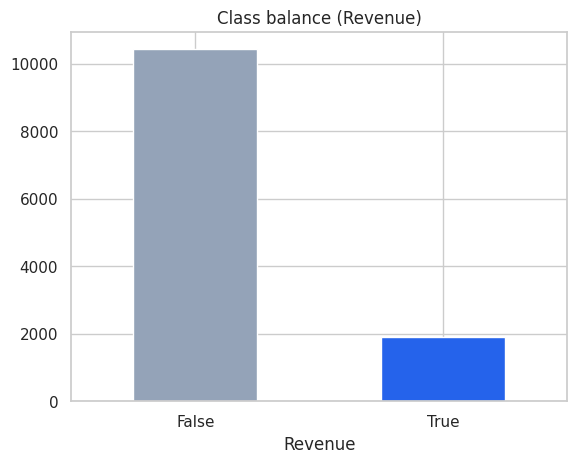

In [ ]:
class_counts = df[TARGET].value_counts()
print(class_counts)
print(f"\nPurchase rate: {df[TARGET].mean():.1%}  |  Majority-class accuracy: {1 - df[TARGET].mean():.1%}")
df[TARGET].value_counts().plot(kind="bar", color=["#94a3b8", "#2563eb"], rot=0, title="Class balance (Revenue)")
plt.show()

**Data-cleaning decisions**
- Exact duplicate rows are dropped (they would let the same session appear in both train and test).
- Negative durations (if any) are clipped to 0 inside the pipeline (`features.add_features`).
- Category-code columns (`OperatingSystems`, `Browser`, `Region`, `TrafficType`) are *codes, not quantities* → treated as categorical.

In [ ]:
n_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Dropped {n_before - len(df)} duplicate rows -> {len(df)} rows left")
df[TARGET] = df[TARGET].astype(int)

Dropped 125 duplicate rows -> 12205 rows left


## 3 · Exploratory data analysis
EDA is done on the full data for understanding only — **no statistics from it feed the model** (all fitting happens later inside the pipeline on the training split).

### 3.1 Univariate

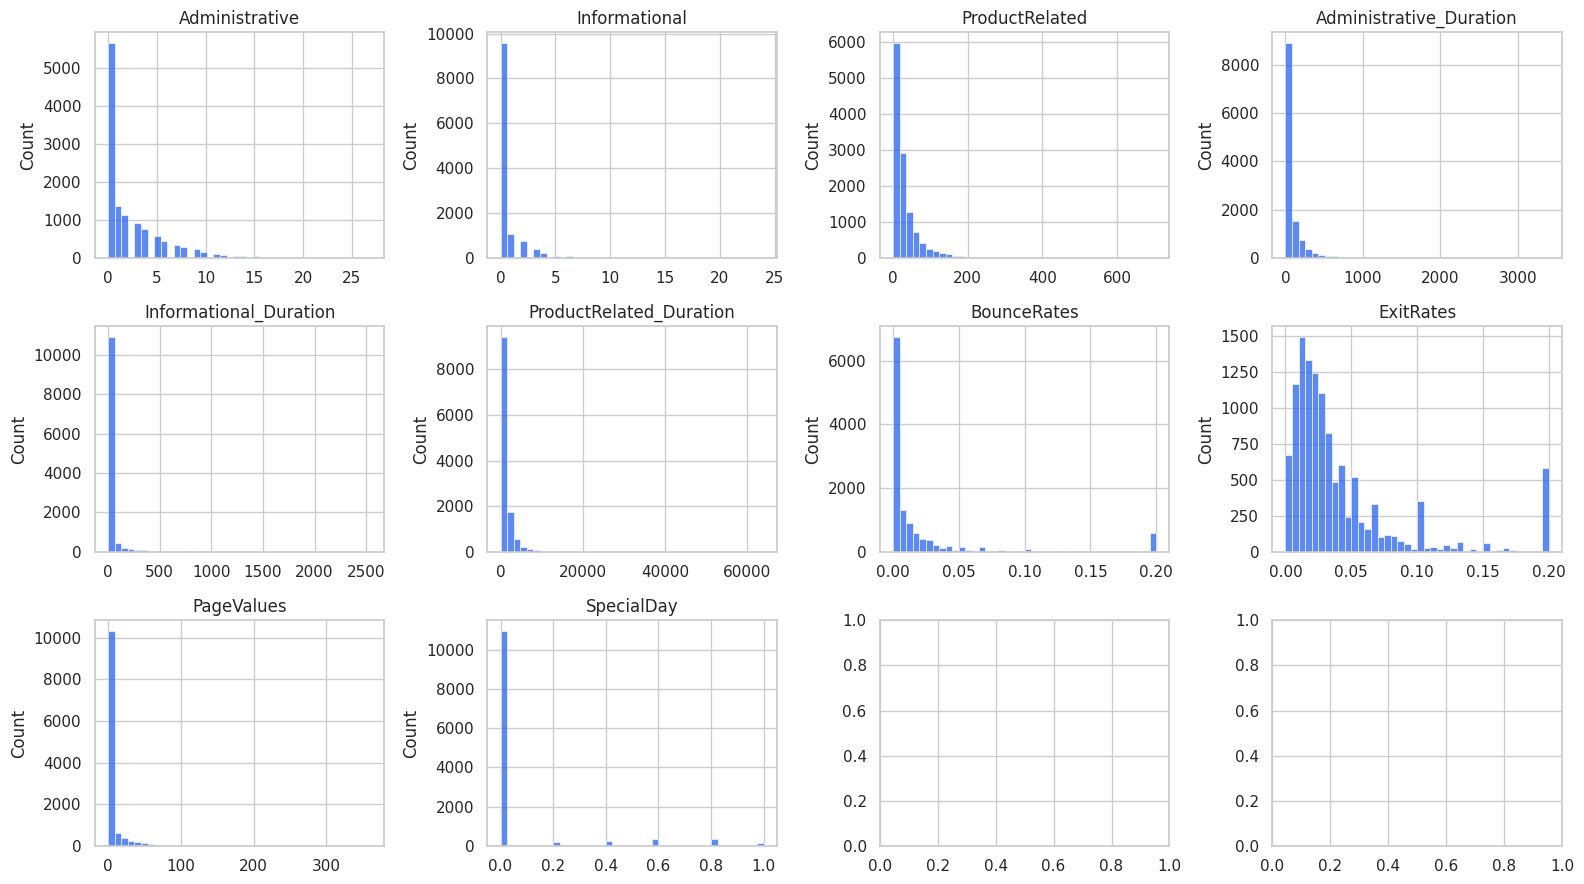

Most numeric columns are strongly right-skewed with many zeros -> log transform for linear models.


In [ ]:
num_cols = PAGE_COUNT_COLS + DURATION_COLS + ["BounceRates", "ExitRates", "PageValues", "SpecialDay"]
fig, axes = plt.subplots(3, 4, figsize=(16, 9))
for ax, c in zip(axes.ravel(), num_cols):
    sns.histplot(df[c], bins=40, ax=ax, color="#2563eb")
    ax.set_title(c)
    ax.set_xlabel("")
plt.tight_layout(); plt.show()
print("Most numeric columns are strongly right-skewed with many zeros -> log transform for linear models.")

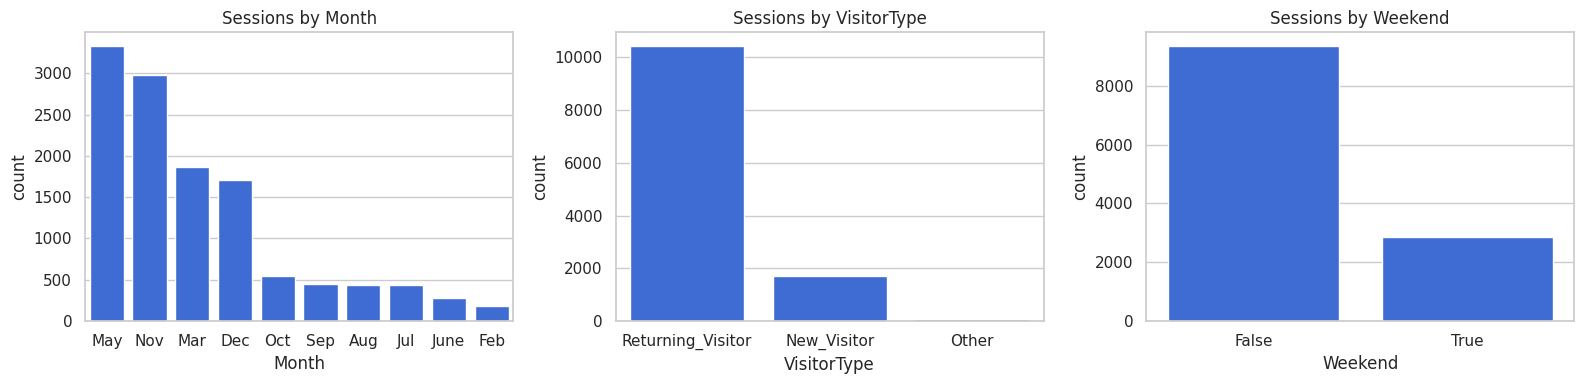

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, c in zip(axes, ["Month", "VisitorType", "Weekend"]):
    order = df[c].value_counts().index
    sns.countplot(data=df, x=c, order=order, ax=ax, color="#2563eb")
    ax.set_title(f"Sessions by {c}")
plt.tight_layout(); plt.show()

### 3.2 Bivariate — what separates buyers from non-buyers?

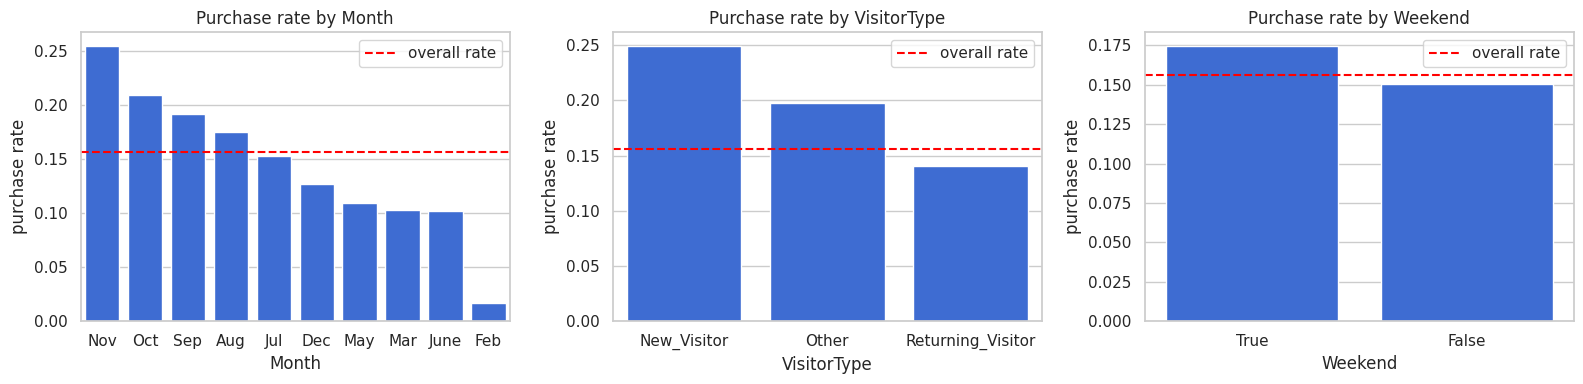

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, c in zip(axes, ["Month", "VisitorType", "Weekend"]):
    rate = df.groupby(c)[TARGET].mean().sort_values(ascending=False)
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=ax, color="#2563eb")
    ax.axhline(df[TARGET].mean(), color="red", ls="--", label="overall rate")
    ax.set_title(f"Purchase rate by {c}"); ax.set_ylabel("purchase rate"); ax.legend()
plt.tight_layout(); plt.show()

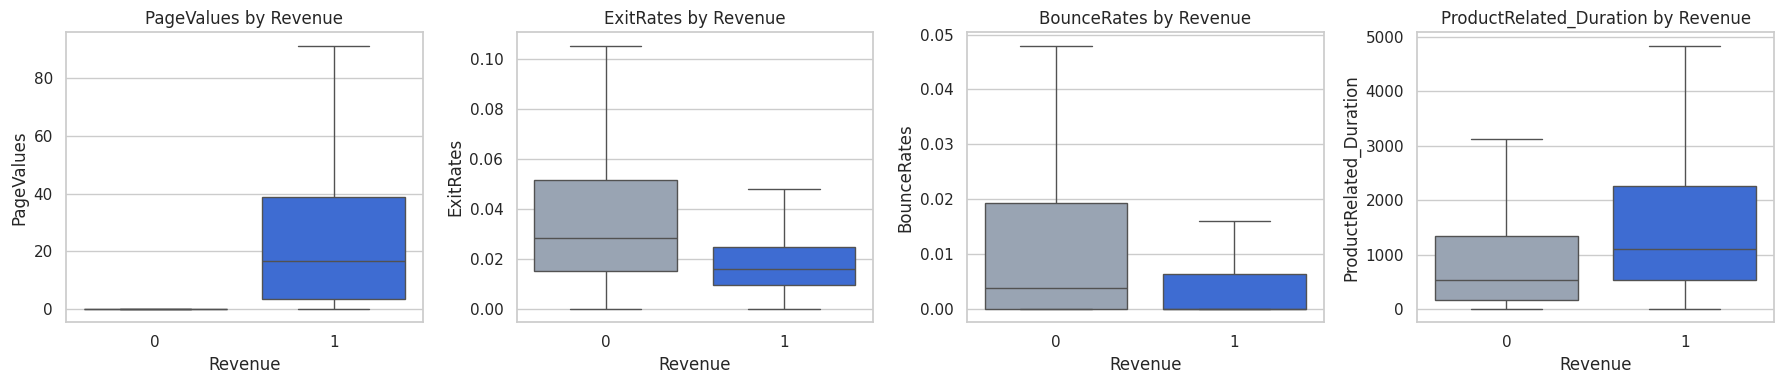

,PageValues,ExitRates,BounceRates,ProductRelated,ProductRelated_Duration
Revenue,,,,,
0,0.000,0.028,0.004,16.0,526.000
1,16.758,0.016,0.000,29.0,1109.906


In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, c in zip(axes, ["PageValues", "ExitRates", "BounceRates", "ProductRelated_Duration"]):
    sns.boxplot(data=df, x=TARGET, y=c, ax=ax, showfliers=False, palette=["#94a3b8", "#2563eb"])
    ax.set_title(f"{c} by Revenue")
plt.tight_layout(); plt.show()

summary = df.groupby(TARGET)[["PageValues", "ExitRates", "BounceRates", "ProductRelated", "ProductRelated_Duration"]].median().round(3)
summary

In [ ]:
# Purchase rate by group (numbers to quote in your insights)
for c in ["VisitorType", "Weekend", "SpecialDay"]:
    print(df.groupby(c)[TARGET].agg(["mean", "count"]).round(3).rename(columns={"mean": "purchase_rate"}), "\n")
print(df.groupby("Month")[TARGET].agg(["mean", "count"]).round(3).sort_values("mean", ascending=False))

                   purchase_rate  count
VisitorType                            
New_Visitor                0.249   1693
Other                      0.198     81
Returning_Visitor          0.141  10431 

         purchase_rate  count
Weekend                      
False            0.151   9346
True             0.175   2859 

            purchase_rate  count
SpecialDay                      
0.0                 0.167  10956
0.2                 0.079    178
0.4                 0.053    243
0.6                 0.083    350
0.8                 0.034    324
1.0                 0.065    154 

        mean  count
Month              
Nov    0.255   2982
Oct    0.209    549
Sep    0.192    448
Aug    0.176    433
Jul    0.153    432
Dec    0.127   1706
May    0.110   3329
Mar    0.103   1860
June   0.102    285
Feb    0.017    181


### 3.3 Multivariate

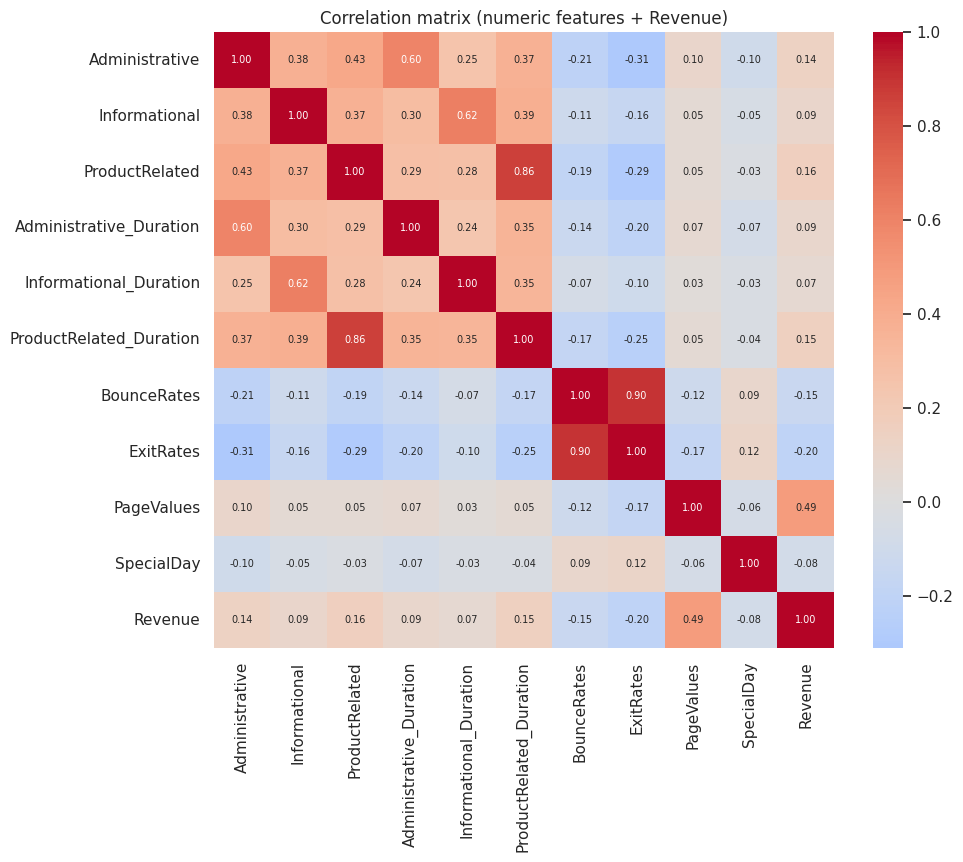

Correlation with Revenue:
PageValues                 0.492
ProductRelated             0.156
ProductRelated_Duration    0.150
Administrative             0.136
Informational              0.094
Administrative_Duration    0.092
Informational_Duration     0.069
SpecialDay                -0.084
BounceRates               -0.145
ExitRates                 -0.204
Name: Revenue, dtype: float64


In [ ]:
corr = df[num_cols + [TARGET]].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7})
plt.title("Correlation matrix (numeric features + Revenue)")
plt.show()
print("Correlation with Revenue:")
print(corr[TARGET].drop(TARGET).sort_values(ascending=False).round(3))

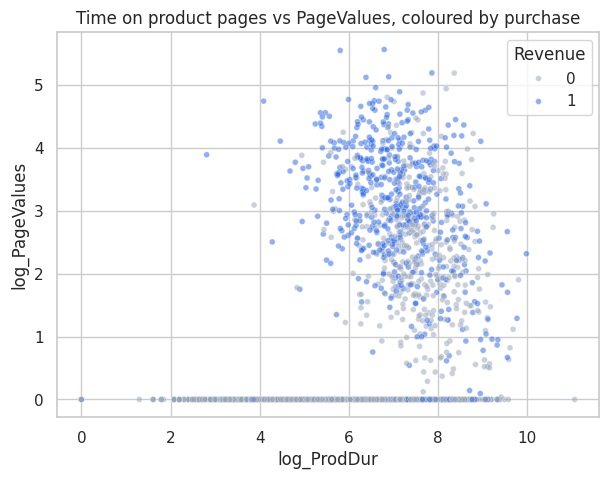

In [ ]:
plot_df = df.assign(log_PageValues=np.log1p(df["PageValues"]), log_ProdDur=np.log1p(df["ProductRelated_Duration"]))
plt.figure(figsize=(7, 5))
sns.scatterplot(data=plot_df.sample(min(4000, len(plot_df)), random_state=SEED), x="log_ProdDur", y="log_PageValues",
                hue=TARGET, palette=["#94a3b8", "#2563eb"], alpha=0.5, s=18)
plt.title("Time on product pages vs PageValues, coloured by purchase"); plt.show()

### 3.4 Written insights   

Based on the correlation analysis, the following insights were observed:

1. **PageValues:** PageValues has the strongest positive correlation with Revenue (0.492). This indicates that sessions with higher PageValues tend to be more associated with purchases.

2. **ExitRates and BounceRates:** Both features have negative correlations with Revenue. ExitRates has a correlation of -0.204, while BounceRates has a correlation of -0.145. This suggests that sessions with higher exit and bounce rates tend to be less associated with purchases.

3. **Product-Related Activity:** ProductRelated has a positive correlation with Revenue (0.156), and ProductRelated_Duration has a positive correlation of 0.150. This suggests that browsing more product pages and spending more time on them are associated with purchasing behavior.

4. **SpecialDay:** SpecialDay has a weak negative correlation with Revenue (-0.084), indicating that its linear relationship with purchasing behavior is relatively weak.

**Note:** Correlation indicates an association between variables and does not necessarily imply causation.

## 4 · Train / test split — before fitting anything
80 % train / 20 % test, **stratified** to keep the purchase rate equal in both. The test set is not touched again until the final evaluation.

In [ ]:
X = df[RAW_FEATURES]
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print("Train:", X_train.shape, f"purchase rate {y_train.mean():.3f}")
print("Test: ", X_test.shape,  f"purchase rate {y_test.mean():.3f}")

Train: (9764, 17) purchase rate 0.156
Test:  (2441, 17) purchase rate 0.156


## 5 · Preprocessing & feature engineering inside a Pipeline

Everything below lives in one scikit-learn `Pipeline`, so cross-validation re-fits it on each training fold (no leakage) and the same object can be saved and used by the app.

1. `add_features` (in `features.py`): clip negative durations, build `TotalPages`, `TotalDuration`, `AvgTimePerPage`, `ProductShare`, apply `log1p` to skewed columns.
2. Scale numeric columns, one-hot encode category columns (`handle_unknown="ignore"` so a new browser code never crashes the app).
3. Model.

In [ ]:
def build_pipeline(model):
    prep = ColumnTransformer([
        ("num", StandardScaler(), NUM_FEATURES),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_FEATURES),
        ("bin", "passthrough", BIN_FEATURES),
    ])
    return Pipeline([("features", FunctionTransformer(add_features)),
                     ("prep", prep),
                     ("model", model)])

# quick sanity check of the engineered table
add_features(X_train.head()).filter(regex="Total|AvgTime|ProductShare|PageValues")

,PageValues,TotalPages,TotalDuration,AvgTimePerPage,ProductShare
7469,3.646944,51,7.136483,3.243664,0.823529
11804,3.559580,30,6.804935,3.435372,1.000000
3250,0.000000,13,6.045400,3.508479,1.000000
204,0.000000,7,6.396096,4.460144,0.714286
4392,0.000000,16,7.377926,4.614667,1.000000


## 6 · Modeling — baseline + three algorithms
Cross-validation (5-fold, stratified) on the **training set only**.

- **Baseline:** always predict the majority class (shows what "doing nothing smart" scores).
- **Logistic Regression**, **Random Forest**, **Gradient Boosting** (`HistGradientBoostingClassifier`) with class weighting for the imbalance.

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {"roc_auc": "roc_auc", "pr_auc": "average_precision", "f1": "f1", "recall": "recall", "precision": "precision"}

models = {
    "Baseline (majority)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=200, class_weight="balanced", n_jobs=-1, random_state=SEED),
    "Gradient Boosting": HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED),
}

rows = []
for name, model in models.items():
    res = cross_validate(build_pipeline(model), X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    rows.append({"model": name, **{k: res[f"test_{k}"].mean() for k in scoring}, "roc_auc_std": res["test_roc_auc"].std()})
cv_default = pd.DataFrame(rows).set_index("model").round(3)
cv_default

,roc_auc,pr_auc,f1,recall,precision,roc_auc_std
model,,,,,,
Baseline (majority),0.500,0.156,0.000,0.000,0.000,0.000
Logistic Regression,0.919,0.666,0.651,0.815,0.542,0.007
Random Forest,0.924,0.737,0.604,0.499,0.768,0.004
Gradient Boosting,0.926,0.740,0.667,0.773,0.586,0.005


## 7 · Hyperparameter tuning (training data only)
`RandomizedSearchCV` with 5-fold CV, optimizing **ROC-AUC**. The test set is still untouched.

In [ ]:
search_spaces = {
    "Logistic Regression": (LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED),
                            {"model__C": loguniform(1e-3, 1e2)}),
    "Random Forest": (RandomForestClassifier(class_weight="balanced", n_jobs=-1, random_state=SEED),
                      {"model__n_estimators": randint(150, 400), "model__max_depth": [4, 6, 8, 12, None],
                       "model__min_samples_leaf": randint(1, 20), "model__max_features": ["sqrt", 0.3, 0.5]}),
    "Gradient Boosting": (HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED),
                          {"model__learning_rate": loguniform(0.01, 0.3), "model__max_depth": [2, 3, 4, 6, None],
                           "model__max_leaf_nodes": randint(8, 48), "model__min_samples_leaf": randint(10, 80),
                           "model__l2_regularization": loguniform(1e-3, 10), "model__max_iter": randint(100, 400)}),
}

tuned, tune_rows = {}, []
for name, (model, space) in search_spaces.items():
    rs = RandomizedSearchCV(build_pipeline(model), space, n_iter=15, scoring="roc_auc", cv=cv,
                            random_state=SEED, n_jobs=-1, refit=True)
    rs.fit(X_train, y_train)
    tuned[name] = rs.best_estimator_
    tune_rows.append({"model": name, "best_cv_roc_auc": round(rs.best_score_, 4), "best_params": rs.best_params_})
tuning_table = pd.DataFrame(tune_rows).set_index("model")
pd.set_option("display.max_colwidth", 200)
tuning_table

,best_cv_roc_auc,best_params
model,,
Logistic Regression,0.9199,{'model__C': 0.0745934328572655}
Random Forest,0.9332,"{'model__max_depth': 8, 'model__max_features': 0.5, 'model__min_samples_leaf': 11, 'model__n_estimators': 352}"
Gradient Boosting,0.9333,"{'model__l2_regularization': 0.40137830238462535, 'model__learning_rate': 0.012115092723815248, 'model__max_depth': 6, 'model__max_iter': 393, 'model__max_leaf_nodes': 9, 'model__min_samples_leaf'..."


In [ ]:
best_name = tuning_table["best_cv_roc_auc"].idxmax()
best_model = tuned[best_name]
print(f"Selected by cross-validation (not by test score): {best_name}")

Selected by cross-validation (not by test score): Gradient Boosting


## 8 · Choosing the decision threshold (still on training data)
A 0.5 cut-off is arbitrary. We get **out-of-fold predicted probabilities on the training set** (each row predicted by a model that never saw it) and look at the precision/recall trade-off to pick the threshold.

Threshold that maximises F1 on out-of-fold training predictions: 0.773


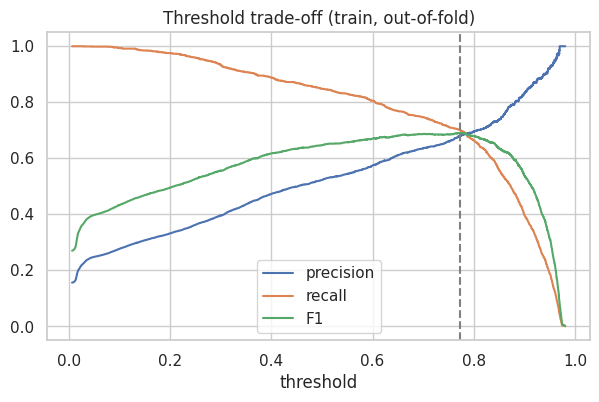

,threshold,precision,recall,flagged_share
0,0.200,0.332,0.975,0.459
1,0.300,0.396,0.934,0.369
2,0.400,0.473,0.889,0.294
3,0.500,0.523,0.848,0.253
4,0.600,0.574,0.805,0.219
5,0.773,0.680,0.701,0.161


In [ ]:
oof_proba = cross_val_predict(best_model, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof_proba)
f1s = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-9, None)
THR_F1 = float(thr[np.argmax(f1s)])
print(f"Threshold that maximises F1 on out-of-fold training predictions: {THR_F1:.3f}")

plt.figure(figsize=(7, 4))
plt.plot(thr, prec[:-1], label="precision"); plt.plot(thr, rec[:-1], label="recall"); plt.plot(thr, f1s, label="F1")
plt.axvline(THR_F1, color="grey", ls="--"); plt.xlabel("threshold"); plt.legend(); plt.title("Threshold trade-off (train, out-of-fold)")
plt.show()

pd.DataFrame({"threshold": [0.2, 0.3, 0.4, 0.5, 0.6, THR_F1]}).assign(
    precision=lambda d: [precision_score(y_train, oof_proba >= t) for t in d.threshold],
    recall=lambda d: [recall_score(y_train, oof_proba >= t) for t in d.threshold],
    flagged_share=lambda d: [(oof_proba >= t).mean() for t in d.threshold]).round(3)

### Three-zone action policy (also from training data only)
The app turns a probability into an action. Because we used class weights, raw probabilities are *shifted upwards* (not calibrated), so zone cut-offs are learned from the out-of-fold training predictions instead of guessed:
- **No action** above `T_BUY` — the model is very sure (≈80 % precision on training folds); a discount would be wasted.
- **Chat assistant** below `T_CHAT` — only ~5 % of real buyers score this low, so these visitors show little intent and may just need help.
- **Coupon** in between — undecided visitors.

In [ ]:
ok = np.where(prec[:-1] >= 0.80)[0]
T_BUY = float(thr[ok[0]]) if len(ok) else float(np.quantile(oof_proba, 0.95))
T_CHAT = float(np.quantile(oof_proba[y_train.values == 1], 0.05))
# guards so that T_CHAT < THR_F1 < T_BUY
if T_CHAT >= THR_F1: T_CHAT = THR_F1 / 2
if T_BUY <= THR_F1: T_BUY = min(0.99, THR_F1 + (1 - THR_F1) / 2)
print(f"T_CHAT = {T_CHAT:.3f}   T_BUY = {T_BUY:.3f}")

def zone(p):
    return np.where(p >= T_BUY, "No action", np.where(p >= T_CHAT, "Coupon", "Chat assistant"))

zones_train = pd.DataFrame({"zone": zone(oof_proba), "bought": y_train.values})
zones_train.groupby("zone")["bought"].agg(sessions="count", purchase_rate="mean").round(3).assign(
    share_of_sessions=lambda d: (d.sessions / d.sessions.sum()).round(3))

T_CHAT = 0.271   T_BUY = 0.882


,sessions,purchase_rate,share_of_sessions
zone,,,
Chat assistant,5909,0.013,0.605
Coupon,2953,0.246,0.302
No action,902,0.800,0.092


## 9 · Final evaluation on the untouched test set

In [ ]:
def metrics_at(model, X_, y_, thr):
    p = model.predict_proba(X_)[:, 1]
    pred = (p >= thr).astype(int)
    return {"roc_auc": roc_auc_score(y_, p), "pr_auc": average_precision_score(y_, p),
            "accuracy": accuracy_score(y_, pred), "precision": precision_score(y_, pred, zero_division=0),
            "recall": recall_score(y_, pred), "f1": f1_score(y_, pred)}

baseline = build_pipeline(DummyClassifier(strategy="most_frequent")).fit(X_train, y_train)
final_rows = {"Baseline (majority)": metrics_at(baseline, X_test, y_test, 0.5)}
for name, m in tuned.items():
    final_rows[f"{name} (tuned)"] = metrics_at(m, X_test, y_test, THR_F1)
test_table = pd.DataFrame(final_rows).T.round(3)
test_table

,roc_auc,pr_auc,accuracy,precision,recall,f1
Baseline (majority),0.500,0.156,0.844,0.000,0.000,0.000
Logistic Regression (tuned),0.926,0.687,0.894,0.657,0.678,0.668
Random Forest (tuned),0.935,0.742,0.904,0.716,0.639,0.675
Gradient Boosting (tuned),0.939,0.757,0.902,0.681,0.709,0.695


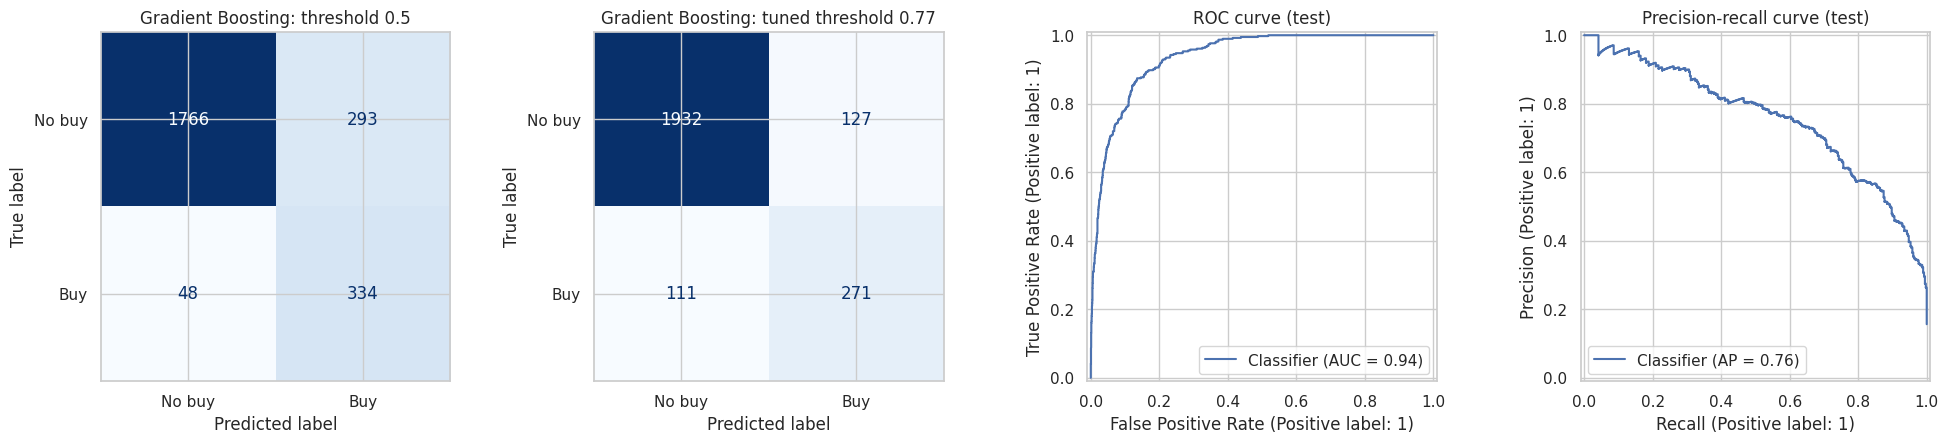

              precision    recall  f1-score   support

      No buy       0.95      0.94      0.94      2059
         Buy       0.68      0.71      0.69       382

    accuracy                           0.90      2441
   macro avg       0.81      0.82      0.82      2441
weighted avg       0.90      0.90      0.90      2441



In [ ]:
best_proba_test = best_model.predict_proba(X_test)[:, 1]
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for thr_, ax, title in [(0.5, axes[0], "threshold 0.5"), (THR_F1, axes[1], f"tuned threshold {THR_F1:.2f}")]:
    ConfusionMatrixDisplay(confusion_matrix(y_test, best_proba_test >= thr_), display_labels=["No buy", "Buy"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{best_name}: {title}")
RocCurveDisplay.from_predictions(y_test, best_proba_test, ax=axes[2]); axes[2].set_title("ROC curve (test)")
PrecisionRecallDisplay.from_predictions(y_test, best_proba_test, ax=axes[3]); axes[3].set_title("Precision-recall curve (test)")
plt.tight_layout(); plt.show()

print(classification_report(y_test, best_proba_test >= THR_F1, target_names=["No buy", "Buy"]))

### Error analysis — who does the model get wrong?

In [ ]:
err = X_test.copy()
err["y"] = y_test.values
err["p"] = best_proba_test
err["pred"] = (best_proba_test >= THR_F1).astype(int)
err["outcome"] = np.select([(err.y == 1) & (err.pred == 1), (err.y == 1) & (err.pred == 0),
                            (err.y == 0) & (err.pred == 1)], ["TP", "FN (missed buyer)", "FP (false alarm)"], "TN")
print(err["outcome"].value_counts(), "\n")
print(err.groupby("outcome")[["PageValues", "ExitRates", "BounceRates", "ProductRelated", "p"]].median().round(3))
print("\nMissed-buyer share by VisitorType:")
print(err[err.y == 1].groupby("VisitorType")["pred"].apply(lambda s: 1 - s.mean()).round(3).rename("missed_share"))

outcome
TN                   1932
TP                    271
FP (false alarm)      127
FN (missed buyer)     111
Name: count, dtype: int64 

                   PageValues  ExitRates  BounceRates  ProductRelated      p
outcome                                                                     
FN (missed buyer)       0.000      0.024        0.004            34.0  0.564
FP (false alarm)       18.585      0.017        0.002            34.0  0.866
TN                      0.000      0.029        0.005            15.0  0.085
TP                     28.404      0.013        0.000            25.0  0.922

Missed-buyer share by VisitorType:
VisitorType
New_Visitor          0.237
Returning_Visitor    0.309
Name: missed_share, dtype: float64


### Error Analysis Insights

The model missed 111 actual buyers (False Negatives). These sessions had a median PageValues of 0.000 and a median predicted probability of 0.564, compared to 28.404 PageValues for correctly identified buyers (True Positives). This suggests that sessions with zero PageValues can be harder for the model to identify as purchases.

The model also produced 127 false alarms (False Positives). Although these visitors did not make a purchase, their median PageValues was 18.585 and their median predicted probability was 0.866, indicating that their browsing behavior appeared similar to actual buyers.

Returning visitors had a higher missed-buyer rate (30.9%) than new visitors (23.7%).

### What drives the predictions? (permutation importance on the test set)

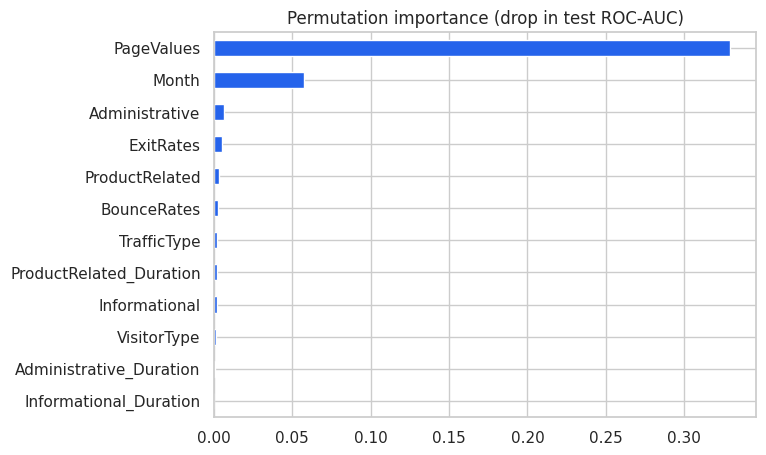

,0
PageValues,0.3295
Month,0.0574
Administrative,0.0064
ExitRates,0.0051
ProductRelated,0.0033
BounceRates,0.0026
TrafficType,0.0019
ProductRelated_Duration,0.0018


In [ ]:
pi = permutation_importance(best_model, X_test, y_test, scoring="roc_auc", n_repeats=10, random_state=SEED, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values()
imp.tail(12).plot(kind="barh", figsize=(7, 5), color="#2563eb", title="Permutation importance (drop in test ROC-AUC)")
plt.show()
imp.sort_values(ascending=False).head(8).round(4)

## 10 · Business simulation (stretch goal)
**Question:** if the site shows a coupon only to the visitors most worth targeting, how many extra sales could it get?

**Targeting rule:** coupon the 10 % of test sessions that are *most undecided* — predicted probability closest to the middle (highest `p × (1 − p)`) — instead of 10 % chosen at random.

**What is measured vs assumed**
- *Measured from the real test labels:* of the targeted visitors, how many bought anyway (a coupon given to them is wasted margin) and how many did not buy (the pool a coupon could convert).
- *Assumed (NOT in the dataset):* a coupon can convert a non-buyer with probability `u × p`, i.e. visitors with more intent are easier to tip over, up to a maximum `u`. This is a stylised what-if; the true effect must come from an A/B test. We show a sensitivity table over `u`.

In [ ]:
p_test = best_proba_test
n_target = int(0.10 * len(X_test))

targeted = np.argsort(-(p_test * (1 - p_test)))[:n_target]
rng = np.random.default_rng(SEED)
random_idx = rng.choice(len(X_test), size=n_target, replace=False)

def group_stats(idx):
    yy = y_test.values[idx]
    return {"visitors": len(idx), "bought anyway (wasted coupons)": int(yy.sum()), "did not buy (convertible pool)": int((1 - yy).sum()),
            "purchase rate in group": round(yy.mean(), 3)}

print("Measured on the real test labels:")
display(pd.DataFrame({"Model-targeted (most undecided)": group_stats(targeted), "Random targeting": group_stats(random_idx)}).T)

rows = []
for u in [0.10, 0.20, 0.30]:
    extra_model = float(((1 - y_test.values[targeted]) * u * p_test[targeted]).sum())
    extra_random = float(((1 - y_test.values[random_idx]) * u * p_test[random_idx]).sum())
    rows.append({"assumed max coupon conversion u": f"{u:.0%}",
                 "extra sales - model targeting": round(extra_model, 1),
                 "extra sales - random targeting": round(extra_random, 1)})
print("\nWhat-if (assumption-based, not measured):")
display(pd.DataFrame(rows))

Measured on the real test labels:


,visitors,bought anyway (wasted coupons),did not buy (convertible pool),purchase rate in group
Model-targeted (most undecided),244.0,47.0,197.0,0.193
Random targeting,244.0,39.0,205.0,0.160



What-if (assumption-based, not measured):


,assumed max coupon conversion u,extra sales - model targeting,extra sales - random targeting
0,10%,9.5,4.4
1,20%,19.1,8.8
2,30%,28.6,13.2


Read this table as an *illustration of how to estimate campaign value*, not as a promise. Real coupon uplift must be measured with an A/B test (random half of visitors get the coupon, compare conversion). State this clearly in your presentation.

## 11 · Business Insights & Limitations

### What the Results Mean

- Our best model, **Gradient Boosting (HistGradientBoostingClassifier)**, achieved a ROC-AUC score of **0.939** on unseen test sessions, compared to **0.500** for the majority-class baseline.
- At the tuned classification threshold, the model identifies **70.9%** of actual buyers (Recall), while **68.1%** of the sessions predicted as purchases are actual buyers (Precision).
- The model also achieved a PR-AUC of **0.757** and an F1-score of **0.695**.
- The most important predictive features include **PageValues, Month, Administrative, ExitRates, and ProductRelated**.

### What the Company Should Do Next

1. Use the three-zone policy in the application:
   - **No Action:** For visitors with a very high purchase probability.
   - **Coupon:** For undecided visitors who may need an incentive.
   - **Chat Assistant:** For visitors with low purchase intent who may need help.
2. Run an **A/B test** on the coupon strategy before implementing it in a real online store, because the business simulation relies on an assumed conversion uplift.
3. Retrain the model regularly to adapt to changes in customer behavior and seasonal shopping patterns.

### Limitations

- The dataset represents one online store over one year. January and April are missing, so the model cannot reliably learn purchasing patterns for these months.
- PageValues is a strong predictive feature, but it depends on the availability of analytics tracking data.
- Correlation does not imply causation. The model predicts who is likely to purchase, but it cannot prove who will be convinced by a coupon.
- Class weighting helps improve recall, but it can make predicted probabilities less calibrated.
- The dataset contains anonymous browsing sessions. User privacy should be respected when applying the model in a real business environment.

### Final Conclusion

This project demonstrates how Machine Learning can be used to analyze online shopping behavior, predict purchase intention, and provide actionable business recommendations through an interactive Streamlit application.

## 12 · Save the pipeline for the web app
The whole pipeline (feature engineering + preprocessing + model) is saved with `joblib`, plus a small JSON file with the dropdown options and the metrics computed above (the app shows them in its "About this model" box).

In [ ]:
joblib.dump(best_model, "models/shopper_pipeline.joblib", compress=3)

meta = {
    "model_name": best_name,
    "threshold_f1": THR_F1,
    "default_t_buy": T_BUY,
    "default_t_chat": T_CHAT,
    "months": sorted(df["Month"].unique().tolist(), key=lambda m: ["Jan","Feb","Mar","Apr","May","June","Jul","Aug","Sep","Oct","Nov","Dec"].index(m) if m in ["Jan","Feb","Mar","Apr","May","June","Jul","Aug","Sep","Oct","Nov","Dec"] else 99),
    "visitor_types": sorted(df["VisitorType"].unique().tolist()),
    "categorical_options": {c: sorted(df[c].astype(str).unique().tolist(), key=lambda v: (len(v), v)) for c in ["OperatingSystems", "Browser", "Region", "TrafficType"]},
    "categorical_defaults": {c: str(df[c].mode()[0]) for c in ["OperatingSystems", "Browser", "Region", "TrafficType"]},
    "test_metrics": {k: round(float(v), 4) for k, v in metrics_at(best_model, X_test, y_test, THR_F1).items()},
    "baseline_test_metrics": {k: round(float(v), 4) for k, v in final_rows["Baseline (majority)"].items()},
    "n_train": int(len(X_train)), "n_test": int(len(X_test)),
    "purchase_rate": round(float(y.mean()), 4),
}
with open("models/metadata.json", "w") as f:
    json.dump(meta, f, indent=2)

# reload & sanity-check: the saved pipeline must reproduce the in-memory predictions on RAW data
reloaded = joblib.load("models/shopper_pipeline.joblib")
assert np.allclose(reloaded.predict_proba(X_test)[:, 1], best_proba_test)
print("Saved models/shopper_pipeline.joblib and models/metadata.json  ✔")
print(json.dumps(meta["test_metrics"], indent=2))

Saved models/shopper_pipeline.joblib and models/metadata.json  ✔
{
  "roc_auc": 0.9387,
  "pr_auc": 0.7567,
  "accuracy": 0.9025,
  "precision": 0.6809,
  "recall": 0.7094,
  "f1": 0.6949
}


In [ ]:
# Pin the library versions used for training: a joblib pipeline must be loaded with the SAME scikit-learn version
import sklearn, pandas, numpy
with open("requirements.txt", "w") as f:
    f.write(f"scikit-learn=={sklearn.__version__}\npandas=={pandas.__version__}\nnumpy=={numpy.__version__}\njoblib=={joblib.__version__}\nstreamlit\n")
print(open("requirements.txt").read())

scikit-learn==1.6.1
pandas==2.2.3
numpy==2.4.6
joblib==1.6.0
streamlit



In [ ]:
# Copy-paste table for the README (baseline vs best model, test set)
readme_table = pd.DataFrame({"Baseline (majority)": meta["baseline_test_metrics"], best_name + " (tuned)": meta["test_metrics"]}).T
print(readme_table.round(3).to_markdown())

|                           |   roc_auc |   pr_auc |   accuracy |   precision |   recall |    f1 |
|:--------------------------|----------:|---------:|-----------:|------------:|---------:|------:|
| Baseline (majority)       |     0.5   |    0.156 |      0.844 |       0     |    0     | 0     |
| Gradient Boosting (tuned) |     0.939 |    0.757 |      0.902 |       0.681 |    0.709 | 0.695 |


### 13 · Final Checklist Before Publishing

- [ ] **Run All** finishes successfully with no errors.
- [x] All written sections are completed using my own project results and analysis.
- [ ] `models/shopper_pipeline.joblib` and `models/metadata.json` are uploaded to my GitHub repository.
- [x] Dataset source is credited: UCI Machine Learning Repository, *Online Shoppers Purchasing Intention Dataset* (Sakar & Kastro).
- [x] This is an individual project by **Zainab Reda**.